In [1]:

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import glob
import pickle as pkl
import plotter_config as pc


In [2]:

sims = ['2022_E5-strong_h0','2022_M2-strong_h0']
var_strs = ['CO','NOx','T']
SAVEDIR = '/glade/u/home/wsmith/NudgeComparison_scripts/vars/'
date0 = '2022-05'   # For h0 files
date1 = '2022-09'


In [5]:

def plot_vardiff(ax, SAVEDIR, sims, var_str, date0, date1, pct=True):
    
    SAVEFILE1 = SAVEDIR + sims[0] + '_' + var_str + '_avgXsect_' + date0 + '_' + date1 + '.pkl'
    with open(SAVEFILE1, 'rb') as f:
        var_zonalmean1 = pkl.load(f)
    
    SAVEFILE2 = SAVEDIR + sims[1] + '_' + var_str + '_avgXsect_' + date0 + '_' + date1 + '.pkl'
    with open(SAVEFILE2, 'rb') as f:
        var_zonalmean2 = pkl.load(f)

    if pct == True: 
        var_diff = (var_zonalmean1 - var_zonalmean2)*100./var_zonalmean1   # Percent change
        levels = np.arange(-20,20.1,5)
    if pct == False: 
        var_diff = var_zonalmean1 - var_zonalmean2
        levels = np.arange(-1,1.01,0.2)
        
    lat = var_zonalmean1["lat"]
    lev = var_zonalmean1["lev"]

    # Load the tropopause from different files because I missed it in the monthly output
    SAVEFILE1 = SAVEDIR + sims[0][:-3] + '_TROP_P_avgXsect_2022-05-01_2022-09-30.pkl'
    with open(SAVEFILE1, 'rb') as f:
        trop1_zonalmean = pkl.load(f)

    #SAVEFILE1 = SAVEDIR + sims[1][:-3] + '_TROP_P_avgXsect_2022-05-01_2022-09-30.pkl'
    #with open(SAVEFILE1, 'rb') as f:
    #    trop2_zonalmean = pkl.load(f)    

    
    cf = ax.contourf(lat, lev, var_diff, levels=levels, cmap=cmap, extend="both")
    
    ax.plot(lat, trop1_zonalmean/100., color='k', linewidth=2)
    #ax.plot(lat, trop2_zonalmean/100., color='k', linewidth=2, linestyle='--') differences imperceptible
    
    ax.invert_yaxis()
    ax.set_yscale('log')
    ax.set_ylim(1000,30)
    ax.set_xticks([-90,-45,0,45,90])

    yticks = [30,100,300,1000]
    ax.set_yticks(yticks)
    ax.set_yticklabels([str(p) for p in yticks])

    ax.set_xlabel("Latitude ($^\circ$)", fontsize=18)
    #ax.set_ylabel("Pressure (hPa)", fontsize=18)
    ax.set_title(var_str, fontsize=18, fontweight='bold')
    ax.tick_params(axis='both', labelsize=18)

    cbar = plt.colorbar(cf, \
        orientation='vertical', spacing='uniform',\
        shrink=0.5, extend='both')#, ticks=levels[:-1])  
    cbar.ax.tick_params(labelsize=18)
    
    if pct == True: cbar.set_label("Percent Difference", fontsize=18)
    if pct == False: cbar.set_label(var_str + ' Difference (' + pc.var_info[var_str]['unit'] + ')', fontsize=18)

    return cf


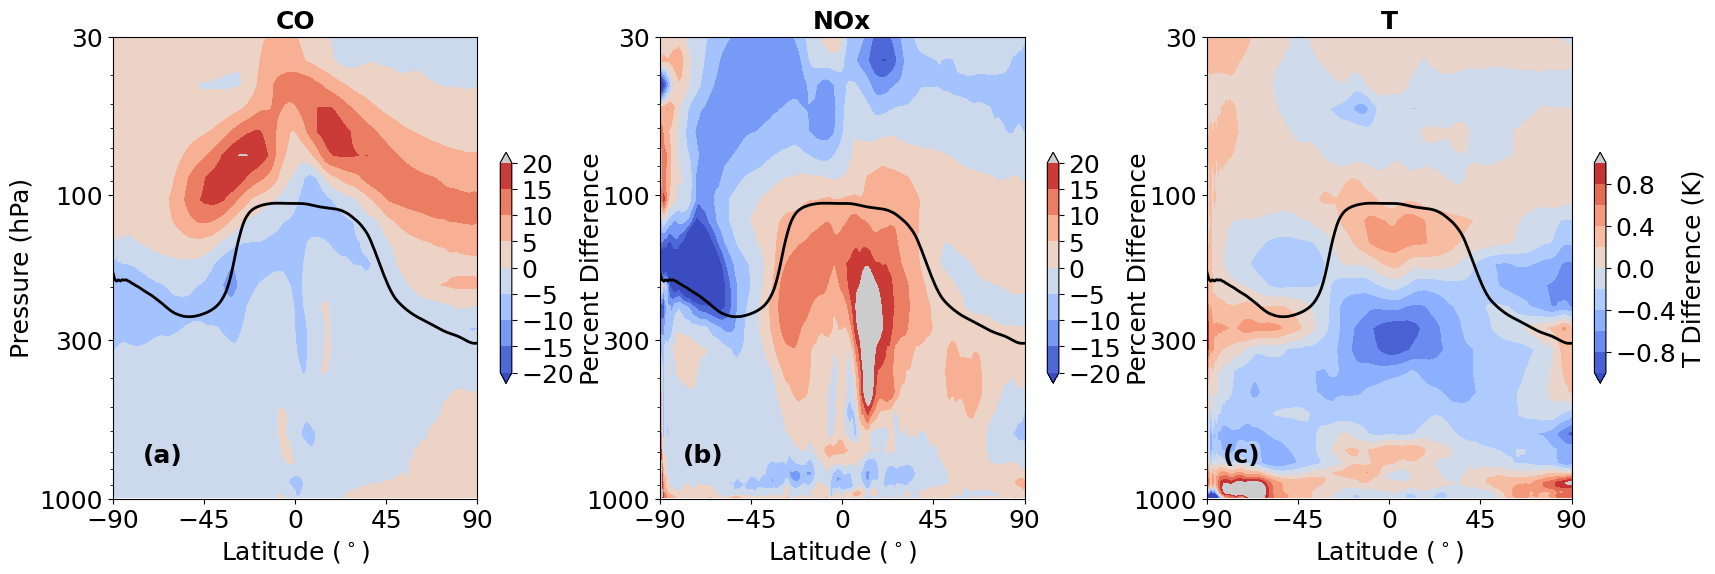

In [9]:

fig = plt.figure(figsize=(20,6))
ax0 = fig.add_subplot(131)
ax1 = fig.add_subplot(132)
ax2 = fig.add_subplot(133)

cmap = plt.get_cmap('coolwarm')
cmap.set_over([0.8,0.8,0.8])

cf = plot_vardiff(ax0, SAVEDIR, sims, var_strs[0], date0, date1, pct=True)
cf = plot_vardiff(ax1, SAVEDIR, sims, var_strs[1], date0, date1, pct=True)
cf = plot_vardiff(ax2, SAVEDIR, sims, var_strs[2], date0, date1, pct=False)

#cbaxes = fig.add_axes([0.13,0.02,0.76,0.02])
#cbaxes = fig.add_axes([0.93,0.2,0.02,0.6])

ax0.set_ylabel("Pressure (hPa)", fontsize=18)

plt.figtext(0.14,0.17,'(a)', fontsize=18, fontweight='bold')
plt.figtext(0.41,0.17,'(b)', fontsize=18, fontweight='bold')
plt.figtext(0.68,0.17,'(c)', fontsize=18, fontweight='bold')

plt.savefig('/glade/u/home/wsmith/NudgeComparison_scripts/plots/Figure4.png')
plt.savefig('/glade/u/home/wsmith/NudgeComparison_scripts/plots/Figure4.pdf')
